I0000 00:00:1793076492.722063    2832 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793076492.919921    2832 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793076494.539497    2832 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.


E0000 00:00:1793076497.985645    2832 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:68

W0000 00:00:1793076497.985794    3111 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1793076498.005892    2832 dlopen_checker.cc:38] Could not load dynamic library 'libcudart.so.12'; dlerror: libcudart.so.12: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/mckb/Git/C

Epoch 1/3


/home/mckb/Git/College/DL/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


92/92 ━━━━━━━━━━━━━━━━━━━━ 58s 615ms/step - accuracy: 0.7238 - loss: 0.7597 - val_accuracy: 0.8556 - val_loss: 0.4430
Epoch 2/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 55s 593ms/step - accuracy: 0.8733 - loss: 0.3783 - val_accuracy: 0.8883 - val_loss: 0.3560
Epoch 3/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 52s 566ms/step - accuracy: 0.9043 - loss: 0.2927 - val_accuracy: 0.8965 - val_loss: 0.3173


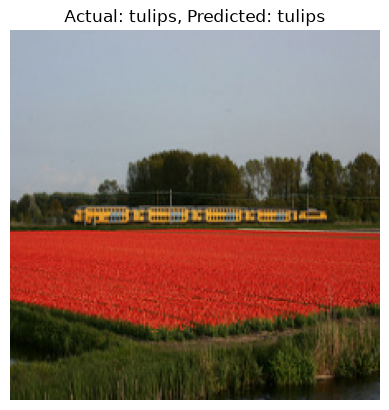

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Sequential
from tensorflow.keras.applications import MobileNetV2, mobilenet_v2

path = tf.keras.utils.get_file("flowers", "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz", untar=True) + "/flower_photos"

train = tf.keras.utils.image_dataset_from_directory(path, validation_split=0.2, subset="training",seed=123, image_size=(224,224))
val = tf.keras.utils.image_dataset_from_directory(path, validation_split=0.2, subset="validation",seed=123, image_size=(224,224))
classes = train.class_names

train = train.map(lambda x,y: (mobilenet_v2.preprocess_input(x),y))
val = val.map(lambda x,y: (mobilenet_v2.preprocess_input(x),y))

base = MobileNetV2(weights="imagenet", include_top=False)
base.trainable = False

model = Sequential([base, layers.GlobalAveragePooling2D(), layers.Dense(5, activation="softmax")])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(train, validation_data=val, epochs=3)

x,y = next(iter(val))
p = np.argmax(model.predict(x[:1], verbose=0)[0])
plt.imshow(((x[0].numpy()+1)*127.5).astype("uint8"))
plt.title(f"Actual: {classes[y[0]]}, Predicted: {classes[p]}")
plt.axis("off")
plt.show()